In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mimlos.mimlos.inventory as inv
import mimlos
import os 
import pandas as pd
from pathlib import Path
import numpy as np
import itertools
import matplotlib.pyplot as plt

In [3]:
file_path = os.getcwd()
fig_dir = Path(file_path) / 'report_figures'
fig_dir.mkdir(parents=True, exist_ok=True)

### Capacity curve plots

In [4]:


# ---------------------------------------------------------------- build test df
code_years = [1941, 1953, 1960, 1965, 1970, 1975, 1977, 1980, 1985, 1990,
              1995, 2005, 2010, 2015, 2020, 2025]
systems = ["WLF-P9", "WLF", "WPB", "SMF", "SBF", "SLF", "SCW", "SIW", 
           "CMF", "CSW", "CIW", "PCW", "PCF1", "PCF2", "RML", "RMC", "URM", "CFS1", "CFS2"]
story_counts = [2, 4]
STORY_HT = 3.5  # m

combos = list(itertools.product(systems, code_years, story_counts))
sys_col, yr_col, n_col = (np.array(c) for c in zip(*combos))
n_rows = len(combos)

test_df = pd.DataFrame({
    "NBC Code Year (Original Building)": yr_col,
    "Description of Seismic Upgrade and Year if Applicable": "",
    "Comprehensive Seismic Upgrade (Y/N)": "",
    "Year Built": yr_col,
    # direction is irrelevant here, so the same system goes in both directions
    "Seismic Force Resisting System in the North-South Direction": sys_col,
    "Seismic Force Resisting System in the East-West Direction": sys_col,
    "Building Height (Total Height Above Ground (m) to Roof Slab)": STORY_HT * n_col.astype(float),
    "Floors Above Grade": n_col.astype(float),
    "Site Class": "C",
    "Ground Floor Plan Area (sq.m.)": (30.0 ** 2) * np.ones(n_rows),
    '"Original" Building Importance Factor Ie': np.ones(n_rows),
    "Occupancy Type": "Public",
    "Roof System": None,
    "Floor System": None,
    "Approved?": "Yes",
})

# ---------------------------------------------------------------- run pipeline
test_inventory = inv.Inventory.load_from_df(test_df)
test_inventory.preprocess_inventory()
test_inventory.estimate_loads()
test_inventory.estimate_Vs()
test_inventory.determine_ductility_parameters()
test_inventory.estimate_capacities()


/home/hyp_pc/oq-vmtk/mimlos/mimlos/nmfs.py:155: UserWarning: Solution has significant residuals
  warnings.warn("Solution has significant residuals")


In [32]:

tst = test_inventory.inventory_df.copy()
# Tag rows with my own columns (assumes no rows were dropped / reordered).
# If preprocess drops rows, merge on index or a unique ID column instead.
assert len(tst) == len(test_df), "rows were dropped/reordered; merge on an ID instead"
tst["system"] = test_df["Seismic Force Resisting System in the North-South Direction"].values
tst["n_stories"] = test_df["Floors Above Grade"].astype(int).values
tst["code_year"] = test_df["NBC Code Year (Original Building)"].values


# ---------------------------------------------------------------- plotting
def plot_capacity(tst, systems=None, years=None, n_stories=None,
                  direction=0, color_by="code_year", ax=None, title=None,
                  right_drift=0.10):
    """
    Plot base-normalized shear vs roof drift ratio for a filtered set of buildings.

    systems / code_years / n_stories : None (= all) or a list of values to keep.
    direction : 0 (N-S) or 1 (E-W). Only matters if the system differs by direction.
    color_by  : 'code_year' or 'system' -- whichever varies across the filtered set.
    """

    nbcc_years = np.array([1941, 1953, 1960, 1965, 1970, 1975, 1977, 1980, 1985, 1990,
              1995, 2005, 2010, 2015, 2020, 2025])
    if years is None:
        years = nbcc_years

    # floor the custom construction year to NBCC years

    code_years = nbcc_years[np.maximum(np.searchsorted(nbcc_years, years, side='right') - 1, 0)]
    df = tst
    if systems is not None:
        df = df[df["system"].isin(systems)]
    if code_years is not None:
        df = df[df["code_year"].isin(code_years)]
    if n_stories is not None:
        df = df[df["n_stories"].isin(n_stories)]
    if df.empty:
        raise ValueError("No rows match the filter")

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))

    keys = sorted(df[color_by].unique())
    if color_by == "code_year":
        # ordered variable -> sequential colormap
        colors = plt.cm.viridis_r(np.linspace(0.1, 1, len(keys)))
    else:
        # categorical variable (e.g. system) -> qualitative colormap
        colors = plt.cm.tab10(np.arange(len(keys)) % 10)
    color_of = dict(zip(keys, colors))
    if color_by == 'code_year':
        styles = itertools.cycle(["--", "-", "-."])
        style_of = dict(zip(keys, styles))
    else:
        styles = itertools.cycle(["-"])
        style_of = dict(zip(keys, styles))

 
    for _, row in df.sort_values(color_by).iterrows():
        theta = np.concatenate([[0.0], row["roof_drift_ratio_capacity"][direction]])
        V = np.concatenate([[0.0], row["story_normalized_shear"][direction][0]])
        ax.plot(theta, V, marker="o", ms=4, lw=1.2,
                linestyle=style_of[row[color_by]],
                color=color_of[row[color_by]],
                label=str(row[color_by]))
 
 
    ax.set_xlim(left=0, right=right_drift)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Roof drift ratio (rad)", fontsize=14)
    ax.set_ylabel("Base normalized shear (V/W)", fontsize=14)
    # ax.set_title(title or "")
    ax.tick_params(axis='both', labelsize=14)
    if color_by == 'code_year':
        ax.legend(fontsize=14, title_fontsize=14, frameon=False, title='NBC year')
    elif color_by == 'system':
        ax.legend(fontsize=14, title_fontsize=14, frameon=False, title='SFRS')
    ax.grid(alpha=0.40)
    ax.figure.tight_layout()
    return ax


In [67]:
tst[(tst['system'] == 'CSW') &
    (tst['n_stories'] == 2) ]

,NBC Code Year (Original Building),Description of Seismic Upgrade and Year if Applicable,Comprehensive Seismic Upgrade (Y/N),Year Built,Seismic Force Resisting System in the North-South Direction,Seismic Force Resisting System in the East-West Direction,Building Height (Total Height Above Ground (m) to Roof Slab),Floors Above Grade,Site Class,Ground Floor Plan Area (sq.m.),...,roof_drift_ratio_capacity,story_forces_kN,story_drift_capacity_m,yield_drift_ratio,effective_yield_drift_ratio,ultimate_drift_ratio,postcap_residual_drift_ratio,system,n_stories,code_year
288,1941,,,1941,CSW,CSW,7.0,2.0,C,900.0,...,"([0.00023848818136894482, 0.001164163022482406...","([[452.25, 452.25, 90.45000000000002, 90.45000...","([[0.0010016503617495682, 0.004889484694426106...","(0.00023848818136894482, 0.00023848818136894482)","([0.00023848818136894482, 0.000238488181368944...","(0.0013696035558616545, 0.0013696035558616545)","(0.0035153157933782474, 0.0035153157933782474)",CSW,2,1941
290,1953,,,1953,CSW,CSW,7.0,2.0,C,900.0,...,"([0.0011007146832412835, 0.0053730601037649504...","([[2087.3076923076915, 2087.3076923076915, 417...","([[0.00462300166961339, 0.022566852435812787, ...","(0.0011007146832412835, 0.0011007146832412835)","([0.0011007146832412835, 0.0011007146832412835...","(0.006321247180899941, 0.006321247180899941)","(0.016224534430976517, 0.016224534430976517)",CSW,2,1953
292,1960,,,1960,CSW,CSW,7.0,2.0,C,900.0,...,"([0.0011007146832412835, 0.0053730601037649504...","([[2087.3076923076915, 2087.3076923076915, 417...","([[0.00462300166961339, 0.022566852435812787, ...","(0.0011007146832412835, 0.0011007146832412835)","([0.0011007146832412835, 0.0011007146832412835...","(0.006321247180899941, 0.006321247180899941)","(0.016224534430976517, 0.016224534430976517)",CSW,2,1960
294,1965,,,1965,CSW,CSW,7.0,2.0,C,900.0,...,"([0.0012683235100075705, 0.006191230619565526,...","([[2405.147727272728, 2442.835227272728, 488.5...","([[0.005326958742031796, 0.02600316860217521, ...","(0.0012683235100075705, 0.0012683235100075705)","([0.0012881975251216493, 0.0012881975251216493...","(0.007283800728900619, 0.007283800728900619)","(0.018695088537511593, 0.018695088537511593)",CSW,2,1965
296,1970,,,1970,CSW,CSW,7.0,2.0,C,900.0,...,"([0.001116124688806662, 0.005448282945217663, ...","([[2116.53, 2149.695, 429.9390000000001, 429.9...","([[0.00468772369298798, 0.022882788369914184, ...","(0.001116124688806662, 0.001116124688806662)","([0.0011336138221070512, 0.0011336138221070512...","(0.0064097446414325444, 0.0064097446414325444)","(0.0164516779130102, 0.0164516779130102)",CSW,2,1970
298,1975,,,1975,CSW,CSW,7.0,2.0,C,900.0,...,"([0.0008928997510453296, 0.004358626356174131,...","([[1693.2240000000006, 1719.7560000000008, 343...","([[0.0037501789543903847, 0.018306230695931347...","(0.0008928997510453296, 0.0008928997510453296)","([0.000906891057685641, 0.000906891057685641],...","(0.005127795713146036, 0.005127795713146036)","(0.013161342330408162, 0.013161342330408162)",CSW,2,1975
300,1977,,,1977,CSW,CSW,7.0,2.0,C,900.0,...,"([0.0008928997510453296, 0.004358626356174131,...","([[1693.2240000000006, 1719.7560000000008, 343...","([[0.0037501789543903847, 0.018306230695931347...","(0.0008928997510453296, 0.0008928997510453296)","([0.000906891057685641, 0.000906891057685641],...","(0.005127795713146036, 0.005127795713146036)","(0.013161342330408162, 0.013161342330408162)",CSW,2,1977
302,1980,,,1980,CSW,CSW,7.0,2.0,C,900.0,...,"([0.0008928997510453296, 0.004358626356174131,...","([[1693.2240000000006, 1719.7560000000008, 343...","([[0.0037501789543903847, 0.018306230695931347...","(0.0008928997510453296, 0.0008928997510453296)","([0.000906891057685641, 0.000906891057685641],...","(0.005127795713146036, 0.005127795713146036)","(0.013161342330408162, 0.013161342330408162)",CSW,2,1980
304,1985,,,1985,CSW,CSW,7.0,2.0,C,900.0,...,"([0.0007930116722813054, 0.005161373112733753,...","([[1503.8041999842314, 1823.4904669876826, 364...","([[0.0033306490235814824, 0.02167

#### per-system

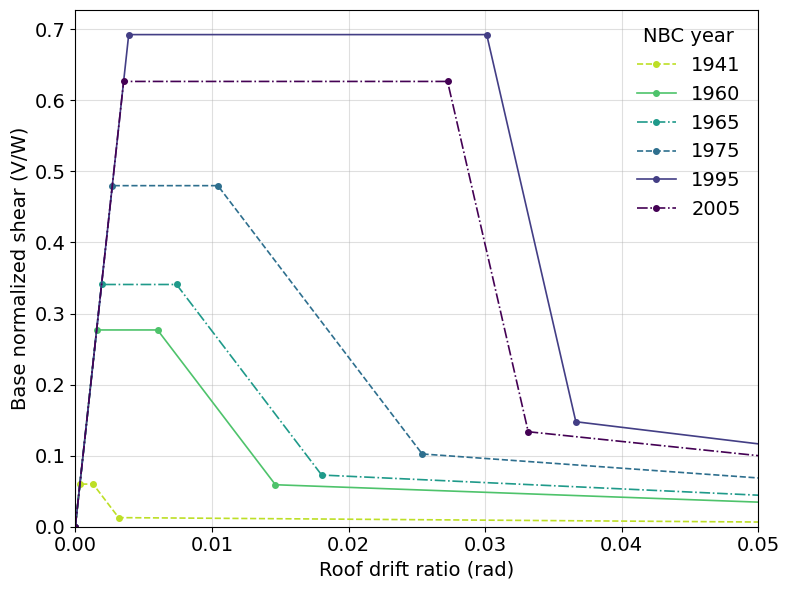

In [34]:
# one system, several code years, one height, single direction
plot_capacity(tst, systems=["WLF"], years=[1941, 1960, 1965, 1975, 1995, 2005], 
              n_stories=[2], direction=0, color_by="code_year", right_drift=0.05)
figpath = fig_dir / 'wlf_eras.png'
plt.savefig(figpath, dpi=300)

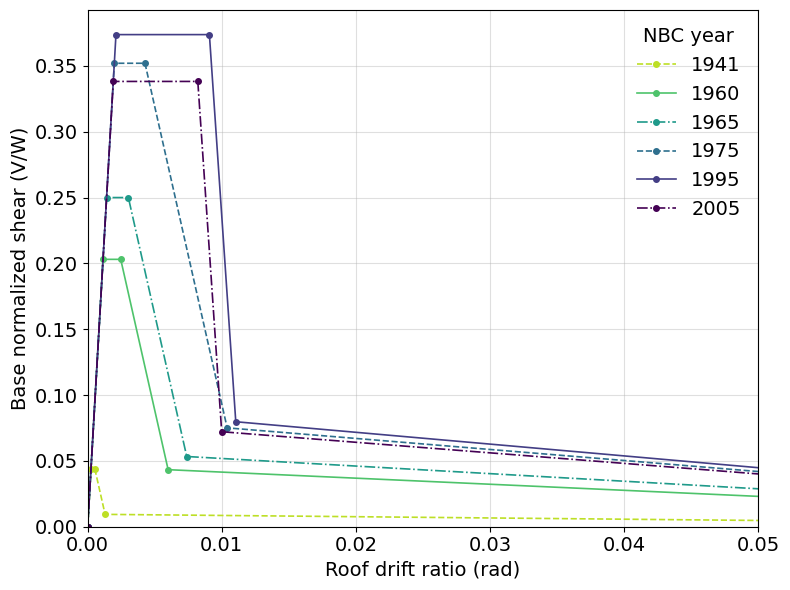

In [9]:
plot_capacity(tst, systems=["WPB"], years=[1941, 1960, 1965, 1975, 1995, 2005], 
              n_stories=[2], direction=0, color_by="code_year", right_drift=0.05)
figpath = fig_dir / 'wpb_eras.png'
plt.savefig(figpath, dpi=300)

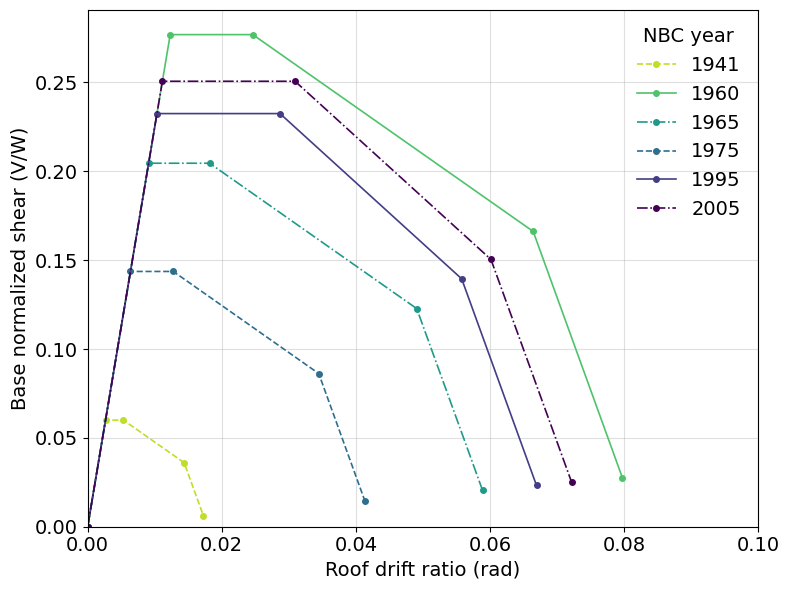

In [10]:
# one system, several code years, one height, single direction
plot_capacity(tst, systems=["SMF"], years=[1941, 1960, 1965, 1975, 1995, 2005], 
              n_stories=[2], direction=0, color_by="code_year")
figpath = fig_dir / 'smf_eras.png'
plt.savefig(figpath, dpi=300)

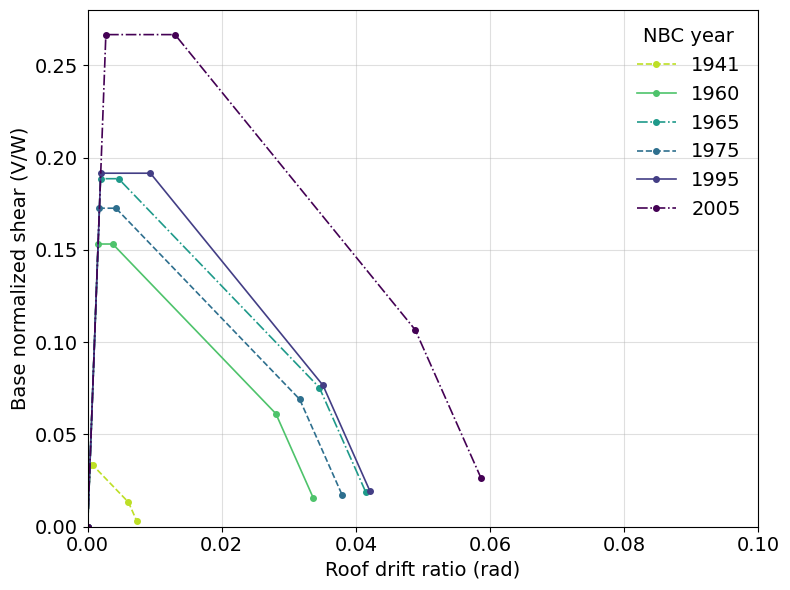

In [11]:
# one system, several code years, one height, single direction
plot_capacity(tst, systems=["SBF"], years=[1941, 1960, 1965, 1975, 1995, 2005], 
              n_stories=[2], direction=0, color_by="code_year")
figpath = fig_dir / 'sbf_eras.png'
plt.savefig(figpath, dpi=300)

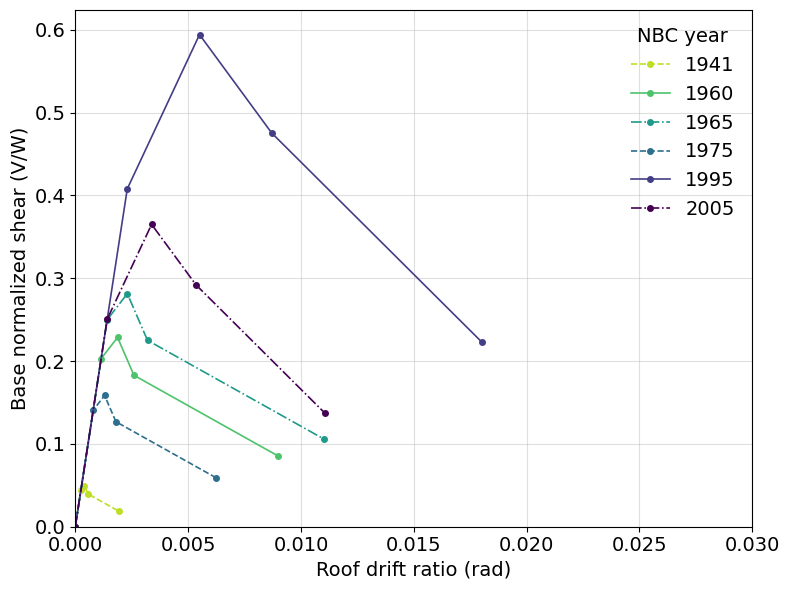

In [12]:
plot_capacity(tst, systems=["CFS1"], years=[1941, 1960, 1965, 1975, 1995, 2005], 
              n_stories=[2], direction=0, color_by="code_year", right_drift=0.03)
figpath = fig_dir / 'cfs1_eras.png'
plt.savefig(figpath, dpi=300)

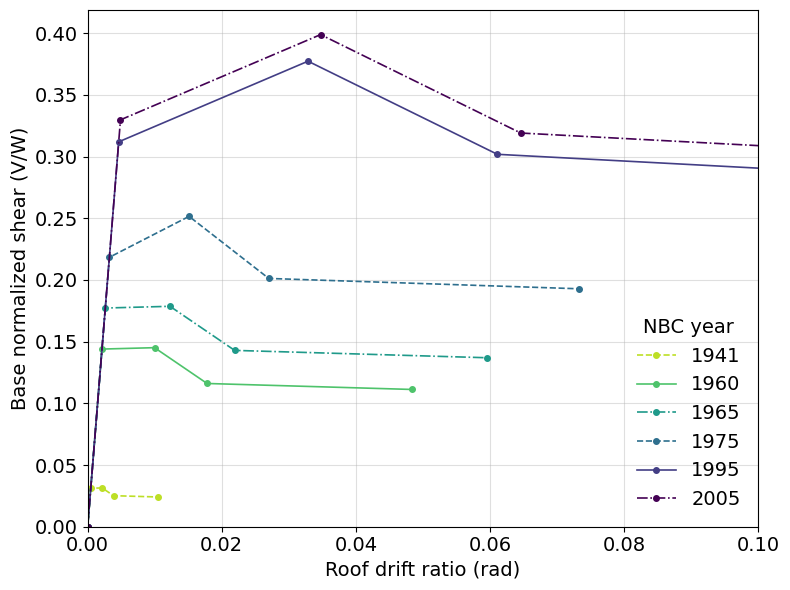

In [13]:
plot_capacity(tst, systems=["CFS2"], years=[1941, 1960, 1965, 1975, 1995, 2005], 
              n_stories=[2], direction=0, color_by="code_year", right_drift=0.1)
figpath = fig_dir / 'cfs2_eras.png'
plt.savefig(figpath, dpi=300)

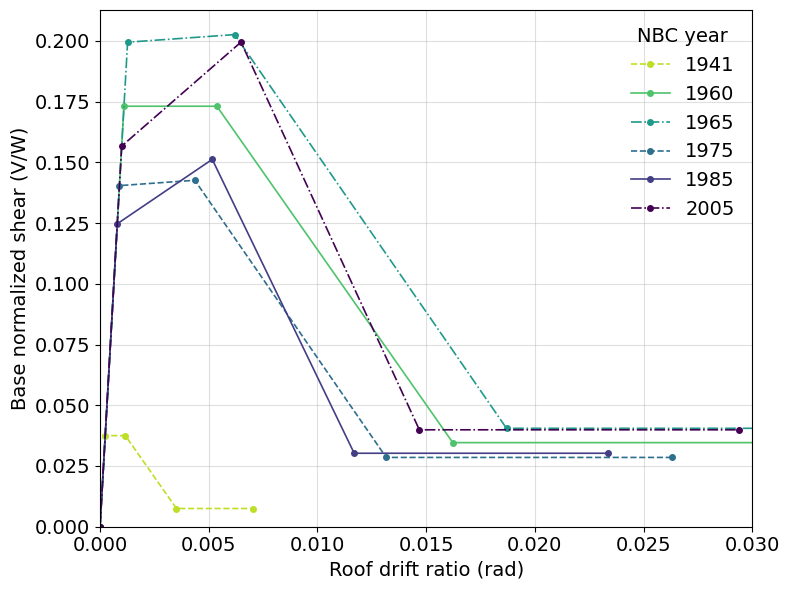

In [14]:
plot_capacity(tst, systems=["CSW"], years=[1941, 1960, 1965, 1975, 1985, 2005], 
              n_stories=[2], direction=0, color_by="code_year", right_drift=0.03)
figpath = fig_dir / 'csw_eras.png'
plt.savefig(figpath, dpi=300)

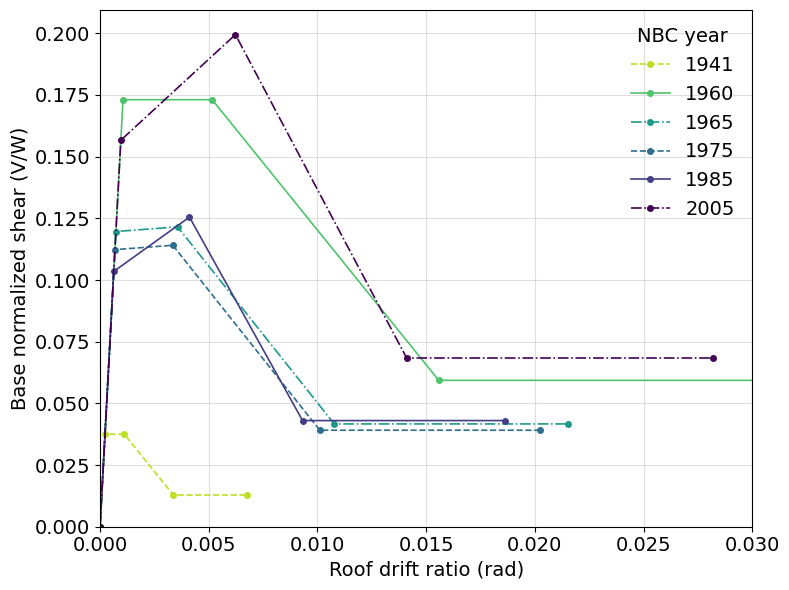

In [15]:
plot_capacity(tst, systems=["SCW"], years=[1941, 1960, 1965, 1975, 1985, 2005], 
              n_stories=[2], direction=0, color_by="code_year", right_drift=0.03)
figpath = fig_dir / 'scw_eras.png'
plt.savefig(figpath, dpi=300)

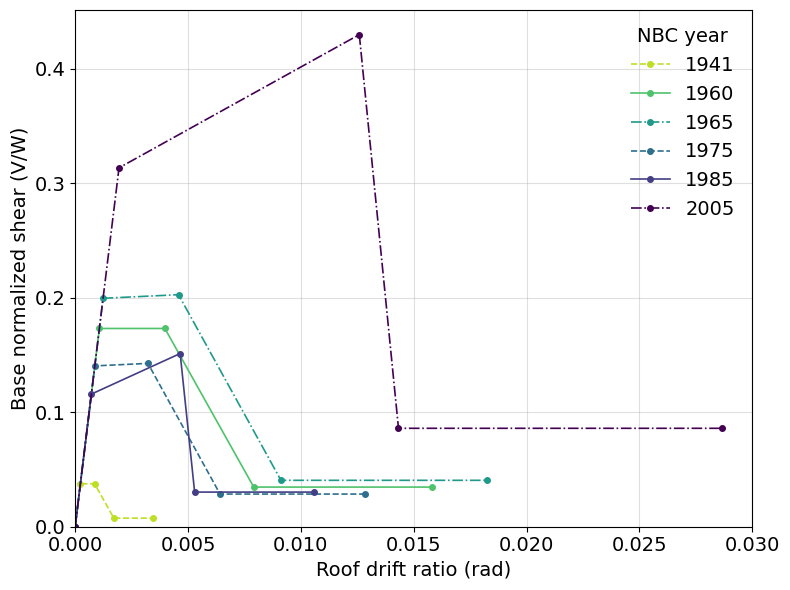

In [16]:
plot_capacity(tst, systems=["PCW"], years=[1941, 1960, 1965, 1975, 1985, 2005], 
              n_stories=[2], direction=0, color_by="code_year", right_drift=0.03)
figpath = fig_dir / 'pcw_eras.png'
plt.savefig(figpath, dpi=300)

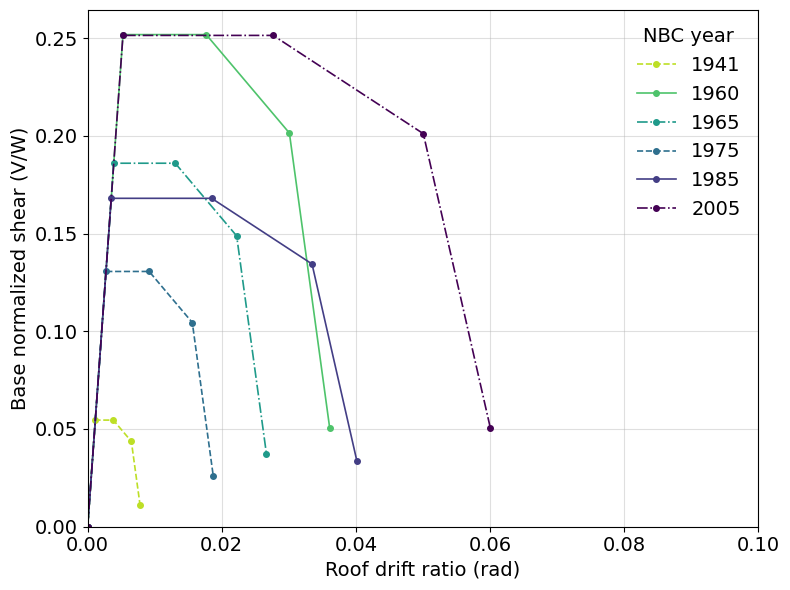

In [19]:
plot_capacity(tst, systems=["CMF"], years=[1941, 1960, 1965, 1975, 1985, 2005], 
              n_stories=[2], direction=0, color_by="code_year", right_drift=0.1)
figpath = fig_dir / 'cmf_eras.png'
plt.savefig(figpath, dpi=300)

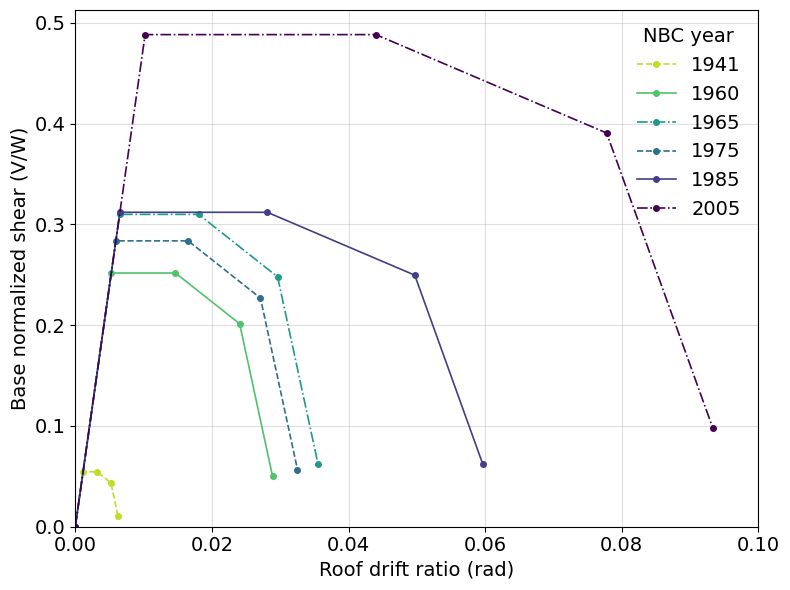

In [20]:
plot_capacity(tst, systems=["PCF2"], years=[1941, 1960, 1965, 1975, 1985, 2005], 
              n_stories=[2], direction=0, color_by="code_year", right_drift=0.1)
figpath = fig_dir / 'pcf2_eras.png'
plt.savefig(figpath, dpi=300)

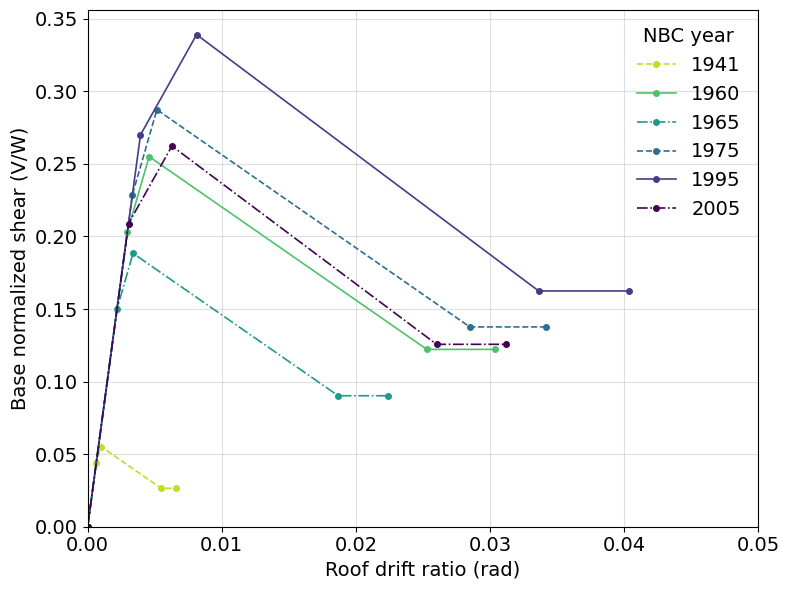

In [24]:
plot_capacity(tst, systems=["CIW"], years=[1941, 1960, 1965, 1975, 1995, 2005], 
              n_stories=[2], direction=0, color_by="code_year", right_drift=0.05)
figpath = fig_dir / 'ciw_eras.png'
plt.savefig(figpath, dpi=300)

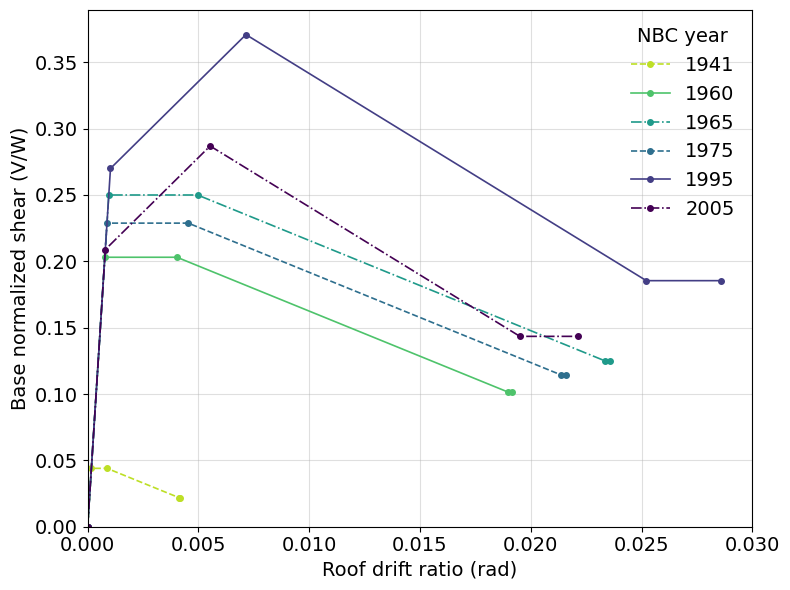

In [26]:
plot_capacity(tst, systems=["RML"], years=[1941, 1960, 1965, 1975, 1995, 2005], 
              n_stories=[2], direction=0, color_by="code_year", right_drift=0.03)
figpath = fig_dir / 'rm_eras.png'
plt.savefig(figpath, dpi=300)

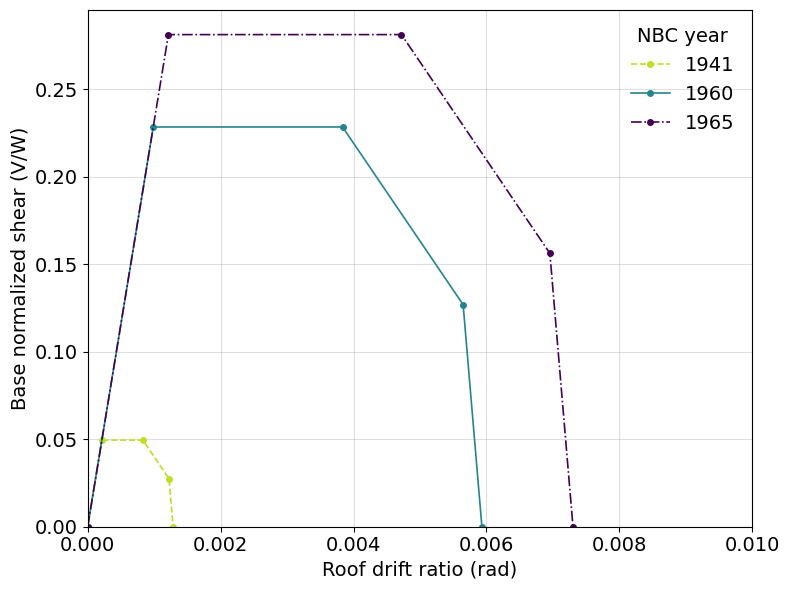

In [29]:
plot_capacity(tst, systems=["URM"], years=[1941, 1960, 1965], 
              n_stories=[2], direction=0, color_by="code_year", right_drift=0.01)
figpath = fig_dir / 'urm_eras.png'
plt.savefig(figpath, dpi=300)

#### All systems, single code-era

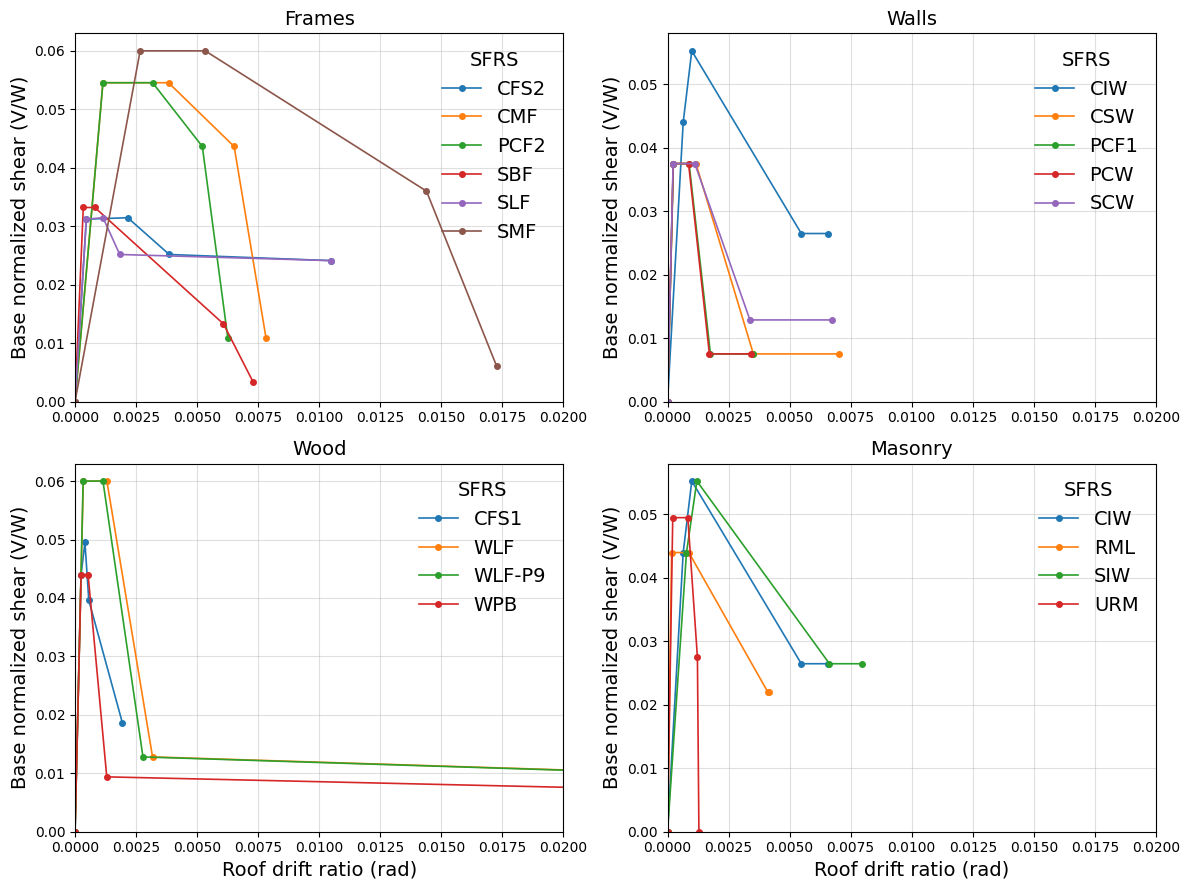

In [62]:
frame_systems   = ["SBF", "SMF", "SLF", "PCF2", "CMF", "CFS2"]
wall_systems    = ["SCW", "CSW", "CIW", "PCW", "PCF1"]
wood_systems    = ["WLF", "WLF-P9", "WPB", "CFS1"]
masonry_systems = ["RML", "URM", "CIW", "SIW"]

system_groups = {
    "Frames":   frame_systems,
    "Walls":    wall_systems,
    "Wood":     wood_systems,
    "Masonry":  masonry_systems,
}

def plot_groups_one_year(tst, groups, year, n_stories=4, direction=0,
                         right_drift=0.10, ncols=2, sharey=False):
    nrows = int(np.ceil(len(groups) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows),
                            sharex=True, sharey=sharey)
    axs = np.atleast_1d(axs).ravel()

    available = set(tst["system"].unique())
    for i, (ax, (name, systems)) in enumerate(zip(axs, groups.items())):
        present = [s for s in systems if s in available]
        missing = [s for s in systems if s not in available]
        if missing:
            print(f"{name}: not in tst, skipped -> {missing}")

        plot_capacity(tst, systems=present, years=[year], n_stories=[n_stories],
                      direction=direction, color_by="system", ax=ax,
                      right_drift=right_drift)
        ax.set_title(name, fontsize=14)
        
        ax.tick_params(axis='both', labelsize=10)
        ax.tick_params(axis='x', labelbottom=True)   

        # label outer axes only
        if i % ncols != 0 and sharey:
            ax.set_ylabel("")
        if i < len(groups) - ncols:
            ax.set_xlabel("")

    for ax in axs[len(groups):]:   # hide unused panels
        ax.set_visible(False)

    # fig.suptitle(f"NBC {year}, {n_stories} storeys", fontsize=16)
    fig.tight_layout()
    return fig, axs

fig, axs = plot_groups_one_year(tst, system_groups, year=1941, 
                                n_stories=2, right_drift=0.02)
figpath = fig_dir / 'cc_1941.png'
plt.savefig(figpath, dpi=300)

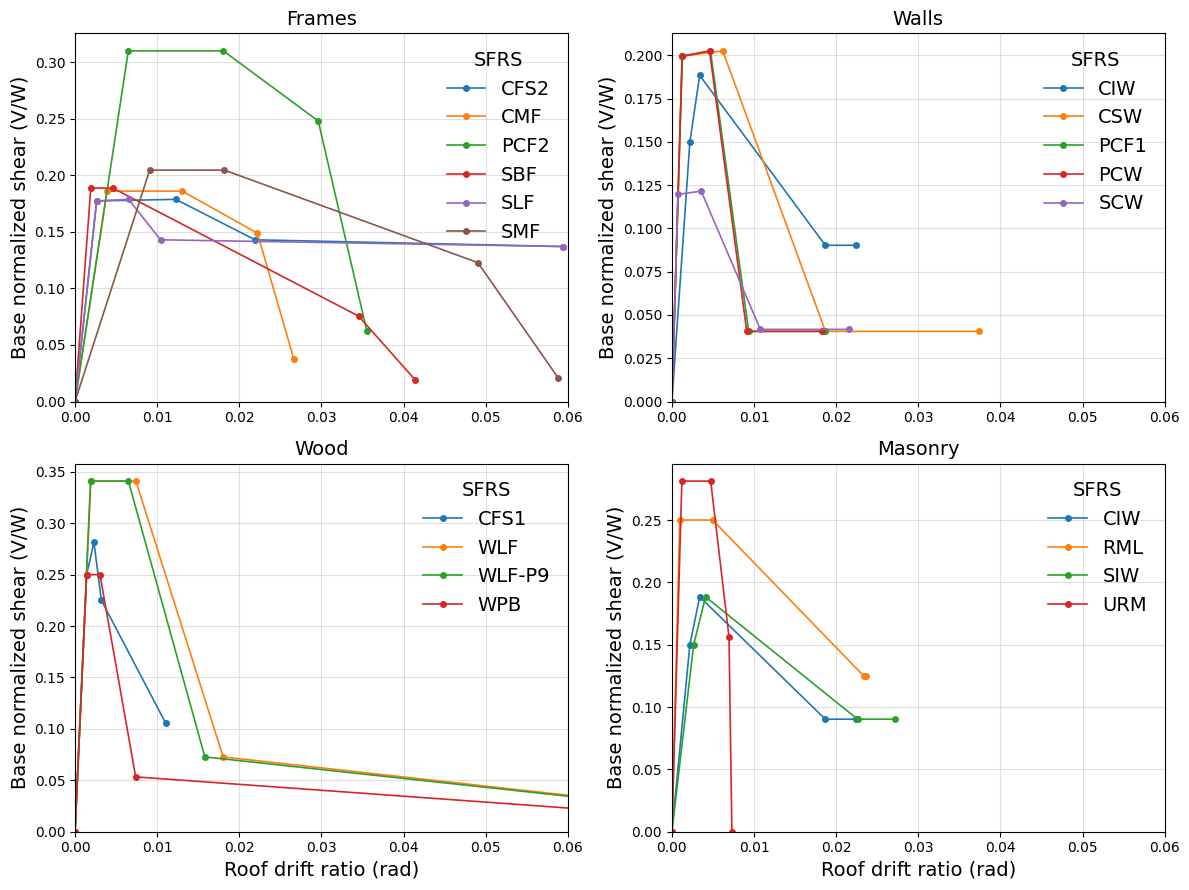

In [63]:

fig, axs = plot_groups_one_year(tst, system_groups, year=1965, 
                                n_stories=2, right_drift=0.06)
figpath = fig_dir / 'cc_1965.png'
plt.savefig(figpath, dpi=300)

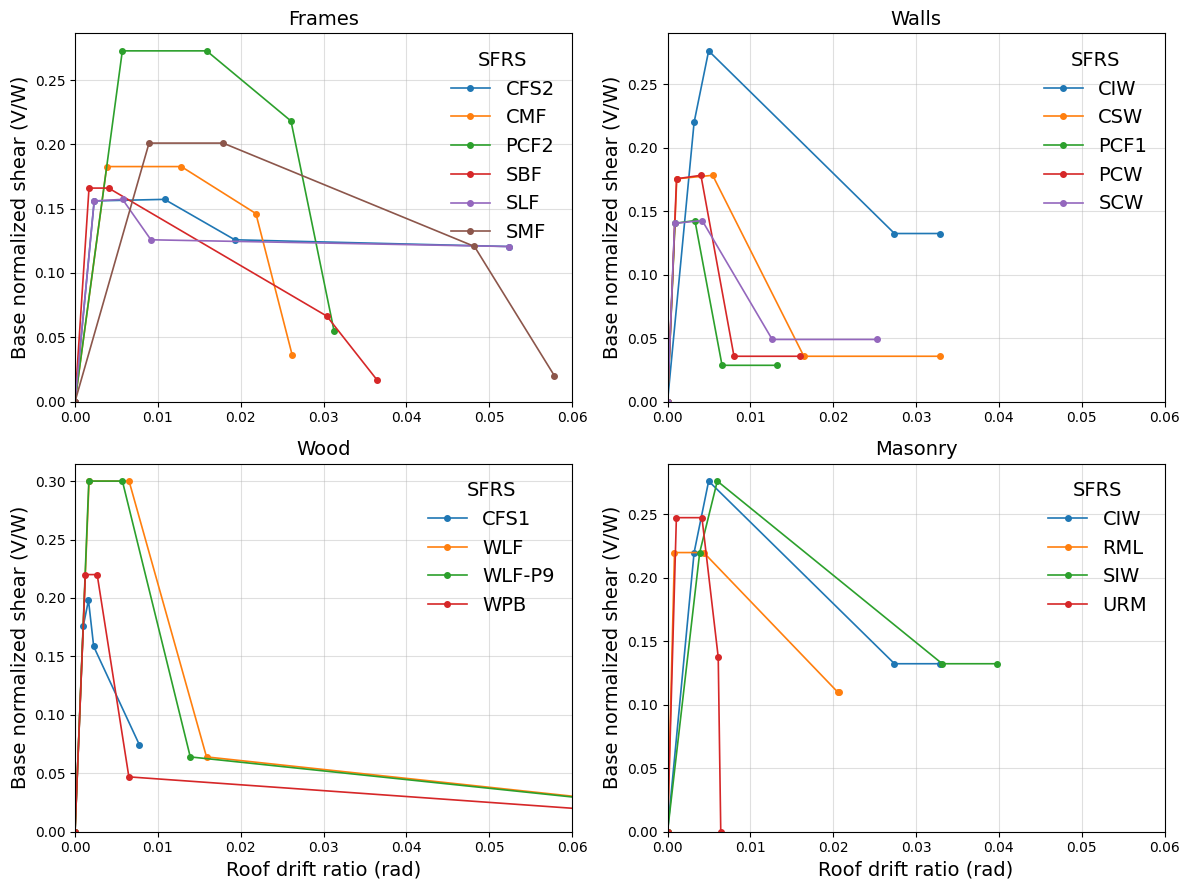

In [64]:
fig, axs = plot_groups_one_year(tst, system_groups, year=1970, 
                                n_stories=2, right_drift=0.06)
figpath = fig_dir / 'cc_1970.png'
plt.savefig(figpath, dpi=300)

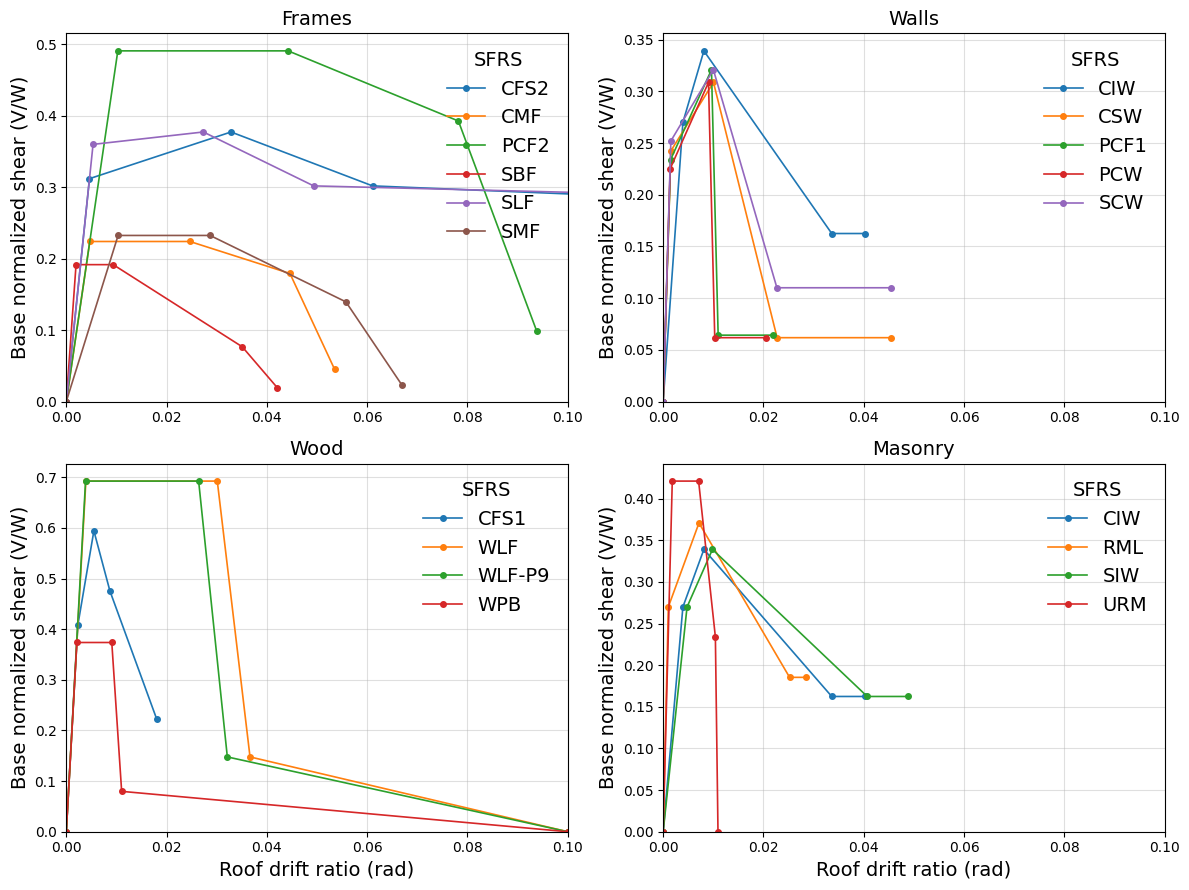

In [65]:
fig, axs = plot_groups_one_year(tst, system_groups, year=1995, 
                                n_stories=2, right_drift=0.1)
figpath = fig_dir / 'cc_1995.png'
plt.savefig(figpath, dpi=300)

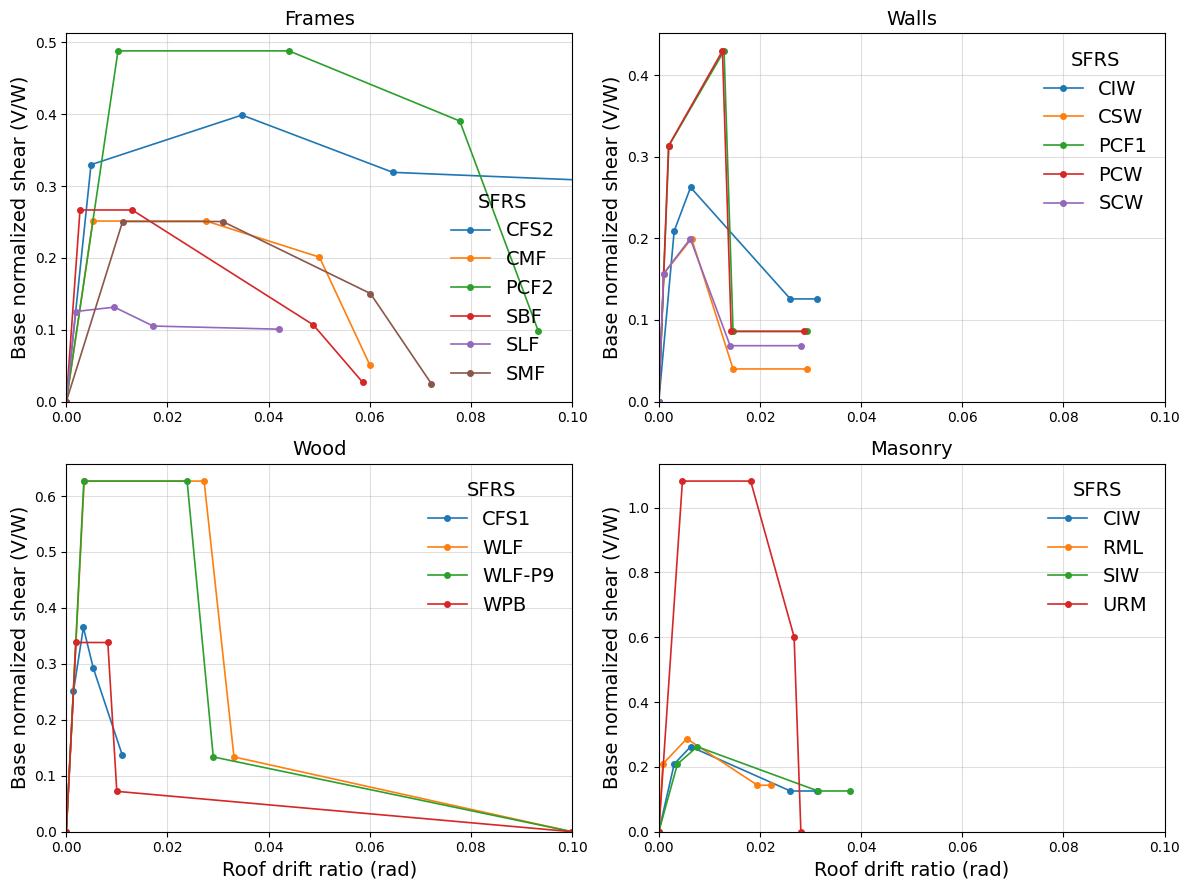

In [66]:
fig, axs = plot_groups_one_year(tst, system_groups, year=2005, 
                                n_stories=2, right_drift=0.1)
figpath = fig_dir / 'cc_2005.png'
plt.savefig(figpath, dpi=300)